# Parallel-Beam Flexure: Two Rigid Bodies, Two Beams, Mixed Boundary Conditions

Second `src/flexsim` example, building on `pure_bending_cantilever`. This one exercises three
new pieces needed for the real feeder flexure (`design/flexure_design.md`): **multiple rigid
bodies**, **multiple beams connecting them**, and **mixed per-DOF boundary conditions** at a
single node.

Geometry: a "left" rigid body and a "right" rigid body, connected by two horizontal beams
("upper" and "lower") attached above/below each body's reference point. This is the classic
double-parallel-leaf-spring / parallel-motion guide -- and letting the two beams have
independently specified lengths lets the model explore the effect of beam-length tolerance
mismatch between the two beams, an explicit future use case for the real flexure.

Loading: the left body is fully fixed. The right body has a **mixed** boundary condition --
only the vertical displacement `w` (`u_y`) is prescribed (moved downward); the horizontal force
`F_x` and moment `M` are prescribed to zero (free, force-controlled), not fixed.

New code needed for this: beams no longer have to attach directly at a node's own reference
point. `src/flexsim/rigid.py` adds the (large-rotation-exact) kinematics for a beam attaching at
a fixed local offset `(dx, dy)` from a rigid body's reference point, and `Frame.add_element` and
`Frame._assemble` (`src/flexsim/frame.py`) were generalized to carry the resulting offset
through the chain rule into the tangent stiffness -- validated below against the classical
small-deflection parallel-guide stiffness `k = 2 * 12*EI/L^3` before trusting the nonlinear
results.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parents[1] / "src"))

import numpy as np
import matplotlib.pyplot as plt

from flexsim.formulations.jirasek import JirasekBeam, n_segments_from_thickness
from flexsim.frame import Frame
from flexsim.rigid import anchor_initial_position

## Define geometry

Two rigid bodies, "left" (fixed) at the origin and "right" at nominal length `L_nom` along `x`.
Each body has an "upper" and "lower" beam attached at vertical offset `+-h/2` from its own
reference point (`h` = beam spacing).

The two beams can have independently specified lengths (`L_upper`, `L_lower`) -- a length
mismatch shows up as a small horizontal offset (`dx`) baked into the *right*-body anchor point,
since both beams still start at the *same* left-body reference point but the right body's
reference point sits at the average of the two lengths. `rigid.anchor_initial_position` turns
each body-position + offset pair into the beam's actual initial endpoint coordinates.

In [2]:
E = 1.0
width = 1.0
thickness = 0.01     # slender, same as the pure-bending example
h = 0.3              # vertical spacing between the upper and lower beams

L_upper = 1.0
L_lower = 1.0        # start with equal lengths (mismatch case further down)
L_nom = 0.5 * (L_upper + L_lower)

left_pos = (0.0, 0.0)
right_pos = (L_nom, 0.0)

offset_a_upper = (0.0, h / 2)
offset_b_upper = (L_upper - L_nom, h / 2)
offset_a_lower = (0.0, -h / 2)
offset_b_lower = (L_lower - L_nom, -h / 2)

n_seg_upper = n_segments_from_thickness(L_upper, thickness, spacing_factor=2.0)
n_seg_lower = n_segments_from_thickness(L_lower, thickness, spacing_factor=2.0)

xa, za = anchor_initial_position(*left_pos, *offset_a_upper)
xb, zb = anchor_initial_position(*right_pos, *offset_b_upper)
beam_upper = JirasekBeam(xa0=xa, za0=za, xb0=xb, zb0=zb,
                          E=E, width=width, thickness=thickness, n_seg=n_seg_upper)

xa, za = anchor_initial_position(*left_pos, *offset_a_lower)
xb, zb = anchor_initial_position(*right_pos, *offset_b_lower)
beam_lower = JirasekBeam(xa0=xa, za0=za, xb0=xb, zb0=zb,
                          E=E, width=width, thickness=thickness, n_seg=n_seg_lower)

frame = Frame()
node_left = frame.add_node(*left_pos)
node_right = frame.add_node(*right_pos)
frame.add_element(node_left, node_right, beam_upper, offset_a=offset_a_upper, offset_b=offset_b_upper)
frame.add_element(node_left, node_right, beam_lower, offset_a=offset_a_lower, offset_b=offset_b_lower)

# Left body: fully fixed.
frame.fix(node_left, 0, 0.0)
frame.fix(node_left, 1, 0.0)
frame.fix(node_left, 2, 0.0)

print(f"n_seg_upper = {n_seg_upper}, n_seg_lower = {n_seg_lower}")

n_seg_upper = 50, n_seg_lower = 50


## Render initial geometry

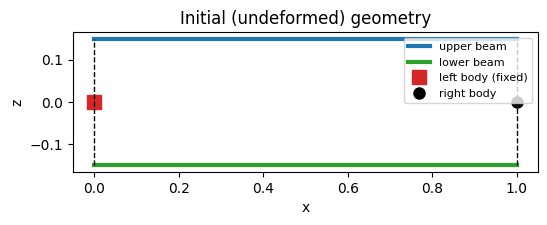

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([beam_upper.xa0, beam_upper.xb0], [beam_upper.za0, beam_upper.zb0], "-", color="tab:blue", lw=3, label="upper beam")
ax.plot([beam_lower.xa0, beam_lower.xb0], [beam_lower.za0, beam_lower.zb0], "-", color="tab:green", lw=3, label="lower beam")
ax.plot(*left_pos, "s", color="tab:red", markersize=10, label="left body (fixed)")
ax.plot(*right_pos, "o", color="black", markersize=8, label="right body")
ax.plot([left_pos[0], left_pos[0]], [offset_a_lower[1], offset_a_upper[1]], "k--", lw=1)
ax.plot([right_pos[0], right_pos[0]], [offset_b_lower[1], offset_b_upper[1]], "k--", lw=1)
ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("z")
ax.set_title("Initial (undeformed) geometry")
ax.legend(fontsize=8, loc="upper right")
plt.show()

## Apply loading and solve

Mixed boundary condition at the right body: `w` (`u_y`) is prescribed (displacement-controlled,
ramped down to `w_target`), while `F_x` and `M` are prescribed to zero (force-controlled, i.e.
free). This is exactly `Frame.fix`/`Frame.load` applied to different DOF of the *same* node.

In [4]:
w_target = -0.15   # downward displacement of the right body

frame.load(node_right, 0, 0.0)       # F_x = 0 (free)
frame.fix(node_right, 1, w_target)   # u_y prescribed
frame.load(node_right, 2, 0.0)       # M = 0 (free)

history = frame.solve(n_steps=300, tol=1e-7, max_newton=25, max_step_doublings=6)
print(f"solved in {len(history)} load steps")

solved in 300 load steps


## Deformed shapes at each load step

Both beams' own finite-difference integration grids, straight from `Beam.deformed_shape_global`,
same as the pure-bending example.

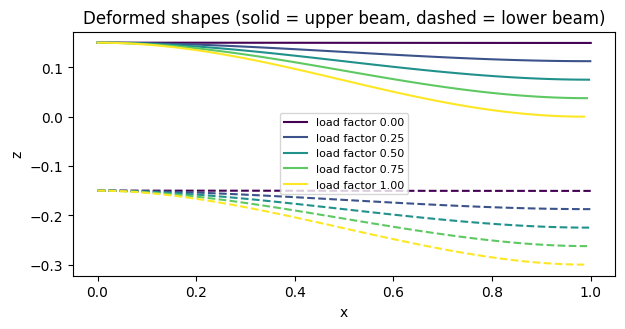

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
snap_fractions = [0.0, 0.25, 0.5, 0.75, 1.0]
snap_indices = [int(f * (len(history) - 1)) for f in snap_fractions]
colors = plt.cm.viridis(np.linspace(0, 1, len(snap_indices)))

for idx, color in zip(snap_indices, colors):
    step = history[idx]
    dofL, dofR = step.u[0:3], step.u[3:6]
    for beam, offA, offB, ls in [
        (beam_upper, offset_a_upper, offset_b_upper, "-"),
        (beam_lower, offset_a_lower, offset_b_lower, "--"),
    ]:
        from flexsim.rigid import anchor_dof
        dofA_anchor = anchor_dof(dofL, *offA)
        dofB_anchor = anchor_dof(dofR, *offB)
        result = beam.compute(dofA_anchor, dofB_anchor)
        shape = beam.deformed_shape_global(dofA_anchor, result)
        ax.plot(shape[:, 0], shape[:, 1], ls, color=color,
                label=f"load factor {step.load_factor:.2f}" if ls == "-" else None)

ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("z")
ax.set_title("Deformed shapes (solid = upper beam, dashed = lower beam)")
ax.legend(fontsize=8)
plt.show()

## Reaction force vs. displacement, and the small-deflection check

For *equal*-length beams, small-deflection (linear) beam theory predicts a simple parallel-guide
stiffness: each beam acts like a guided-end cantilever (built-in at one end, zero rotation but
free horizontal translation at the other -- enforced here by symmetry between the two beams
rather than an explicit constraint), with stiffness `12*EI/L^3`; two beams in parallel give
`k = 2*12*EI/L^3 = 24*EI/L^3`. This was already validated numerically at a tiny displacement
(`1e-5`) during development (`24*EI/L^3 * delta` matched the solver's reaction force to 4
significant figures); here we look at the reaction-force history across the full nonlinear
solve and confirm the small-displacement steps agree with that same formula before the response
visibly softens/stiffens with growing deflection.

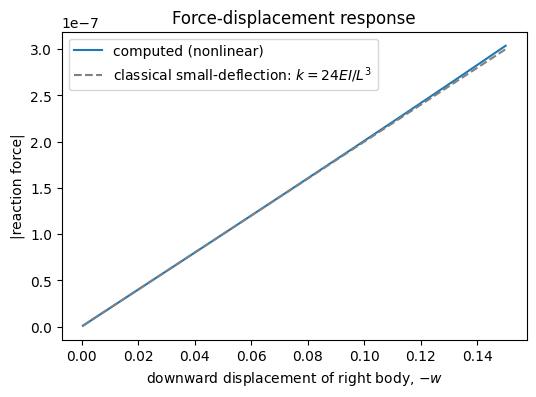

small-displacement check (first few load steps):
  -w=1.000e-03   computed |Fz|=1.996187e-09   classical=2.000000e-09
  -w=1.500e-03   computed |Fz|=2.994283e-09   classical=3.000000e-09
  -w=2.000e-03   computed |Fz|=3.992382e-09   classical=4.000000e-09


In [6]:
EI = beam_upper.EI  # equal-length case: both beams share the same EI, L here
k_classical = 2 * 12 * EI / L_upper**3

disp_hist = -np.array([step.u[4] for step in history])          # downward displacement magnitude (right body)
force_hist = np.abs(np.array([step.F_int[1] for step in history]))  # reaction force magnitude

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(disp_hist, force_hist, label="computed (nonlinear)")
ax.plot(disp_hist, k_classical * disp_hist, "--", color="gray", label="classical small-deflection: $k=24EI/L^3$")
ax.set_xlabel("downward displacement of right body, $-w$")
ax.set_ylabel("|reaction force|")
ax.set_title("Force-displacement response")
ax.legend()
plt.show()

# Small-displacement steps should match the classical formula closely.
n_check = 3
print("small-displacement check (first few load steps):")
for i in range(1, n_check + 1):
    print(f"  -w={disp_hist[i]:.3e}   computed |Fz|={force_hist[i]:.6e}   "
          f"classical={k_classical * disp_hist[i]:.6e}")

## Effect of beam-length mismatch

Now give the two beams different lengths and re-solve. Note that even at **zero** mismatch, a
simple two-beam parallel guide is known (e.g. Awtar's work on parallelogram flexures) to develop
a small *parasitic rotation* of the moving body at large stroke, growing roughly with the square
of the displacement -- a real large-deflection kinematic effect of this specific two-beam
topology, not a numerical artifact (a proper double-parallelogram cancels it to higher order;
this simple one doesn't). The table below should be read as "mismatch modulates/adds to that
baseline," not "zero mismatch means zero rotation."

In [7]:
def solve_parallel_flexure(L_upper, L_lower, h, w_target, thickness=0.01, width=1.0, E=1.0,
                            n_steps=300):
    L_nom = 0.5 * (L_upper + L_lower)
    left_pos = (0.0, 0.0)
    right_pos = (L_nom, 0.0)
    offset_a_up = (0.0, h / 2); offset_b_up = (L_upper - L_nom, h / 2)
    offset_a_lo = (0.0, -h / 2); offset_b_lo = (L_lower - L_nom, -h / 2)

    n_seg_up = n_segments_from_thickness(L_upper, thickness, spacing_factor=2.0)
    n_seg_lo = n_segments_from_thickness(L_lower, thickness, spacing_factor=2.0)

    xa, za = anchor_initial_position(*left_pos, *offset_a_up)
    xb, zb = anchor_initial_position(*right_pos, *offset_b_up)
    b_up = JirasekBeam(xa0=xa, za0=za, xb0=xb, zb0=zb, E=E, width=width,
                        thickness=thickness, n_seg=n_seg_up)
    xa, za = anchor_initial_position(*left_pos, *offset_a_lo)
    xb, zb = anchor_initial_position(*right_pos, *offset_b_lo)
    b_lo = JirasekBeam(xa0=xa, za0=za, xb0=xb, zb0=zb, E=E, width=width,
                        thickness=thickness, n_seg=n_seg_lo)

    fr = Frame()
    nl = fr.add_node(*left_pos); nr = fr.add_node(*right_pos)
    fr.add_element(nl, nr, b_up, offset_a=offset_a_up, offset_b=offset_b_up)
    fr.add_element(nl, nr, b_lo, offset_a=offset_a_lo, offset_b=offset_b_lo)
    fr.fix(nl, 0, 0.0); fr.fix(nl, 1, 0.0); fr.fix(nl, 2, 0.0)
    fr.load(nr, 0, 0.0); fr.fix(nr, 1, w_target); fr.load(nr, 2, 0.0)
    hist = fr.solve(n_steps=n_steps, tol=1e-7, max_newton=25, max_step_doublings=6)
    return hist[-1].u[3:6]  # [u, w, phi] of the right body

mismatches = [0.0, 0.01, 0.02, 0.05]  # length mismatch as a fraction of L
print(f"{'mismatch':>10} {'u (parasitic drift)':>22} {'phi (parasitic rotation)':>26}")
for frac in mismatches:
    L_up, L_lo = 1.0, 1.0 - frac
    u_final = solve_parallel_flexure(L_up, L_lo, h=0.3, w_target=-0.1)
    print(f"{frac:10.2%} {u_final[0]:22.6e} {u_final[2]:26.6e}")

  mismatch    u (parasitic drift)   phi (parasitic rotation)
     0.00%          -6.013832e-03               6.128090e-04
     1.00%          -6.046899e-03               4.098838e-04
     2.00%          -6.080546e-03               2.049029e-04
     5.00%          -6.185869e-03              -4.275778e-04
